# Lung cancer Conformer + Grad-CAM (Kaggle version)

**Setup before Run All**
1. Right sidebar -> **+ Add Input** -> search *Chest CT-Scan images* (mohamedhanyyy) -> add it.
2. Session options -> **Accelerator -> GPU T4 x2 / P100**.
3. Run all cells. The last two cells give a Grad-CAM for any test image you choose.

In [1]:
import os, warnings, random, math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision.transforms as transforms
from PIL import Image
from tqdm import tqdm
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, roc_curve, auc,
    f1_score, precision_score, recall_score, accuracy_score
)
import cv2
from scipy import ndimage

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device  : {device}")
print(f"GPU     : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"PyTorch : {torch.__version__}")

# Must show cuda. If it says cpu: Kaggle right sidebar -> Session options ->
# Accelerator -> GPU T4 x2 (or P100), then restart the session.


Device  : cuda
GPU     : Tesla T4
PyTorch : 2.11.0+cu130


In [2]:
def find_base():
    """Find the folder that contains train/ valid/ test/ under /kaggle/input."""
    for root, dirs, _ in os.walk("/kaggle/input"):
        if {"train", "valid", "test"}.issubset(set(dirs)):
            return root
    raise FileNotFoundError(
        "No train/valid/test folders found. Add the 'Chest CT-Scan images' "
        "dataset via  + Add Input  in the right sidebar.")

BASE       = find_base()
OUTPUT_DIR = "/kaggle/working/outputs"
print("Dataset folder:", BASE)
os.makedirs(OUTPUT_DIR, exist_ok=True)
MODEL_PATH = os.path.join(OUTPUT_DIR, "lung_cancer_conformer.pth")

IMAGE_SIZE   = 224          # standard for patch-based models
BATCH_SIZE   = 16
NUM_CLASSES  = 4
MAX_EPOCHS   = 150
INITIAL_LR   = 3e-4
DROPOUT_RATE = 0.3

CLASS_NAMES = [
    "adenocarcinoma",
    "large_cell_carcinoma",
    "squamous_cell_carcinoma",
    "normal"
]

print("Config ready ✓")
print(f"Image size : {IMAGE_SIZE}")
print(f"Epochs     : {MAX_EPOCHS}")
print(f"LR         : {INITIAL_LR}")

Dataset folder: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data
Config ready ✓
Image size : 224
Epochs     : 150
LR         : 0.0003


In [3]:
ALL_CLASS_MAP = {
    "adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib"       : 0,
    "large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa"    : 1,
    "squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa" : 2,
    "normal"                                             : 3,
    "adenocarcinoma"                                     : 0,
    "large.cell.carcinoma"                               : 1,
    "squamous.cell.carcinoma"                            : 2,
}

all_paths, all_labels = [], []
for split in ["train", "valid", "test"]:
    split_dir = os.path.join(BASE, split)
    for folder_name, label_idx in ALL_CLASS_MAP.items():
        cls_dir = os.path.join(split_dir, folder_name)
        if not os.path.exists(cls_dir):
            continue
        imgs = [f for f in sorted(os.listdir(cls_dir))
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        all_paths  += [os.path.join(cls_dir, f) for f in imgs]
        all_labels += [label_idx] * len(imgs)

print(f"Total images: {len(all_paths)}")
print("\nPer class:")
for i, name in enumerate(CLASS_NAMES):
    count = sum(1 for l in all_labels if l == i)
    print(f"  {name}: {count}")

tr_paths, tmp_paths, tr_labels, tmp_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.30, random_state=SEED, stratify=all_labels)
vl_paths, ts_paths, vl_labels, ts_labels = train_test_split(
    tmp_paths, tmp_labels,
    test_size=0.50, random_state=SEED, stratify=tmp_labels)

print(f"\nTrain : {len(tr_paths)}")
print(f"Val   : {len(vl_paths)}")
print(f"Test  : {len(ts_paths)}")

counts = Counter(tr_labels)
total  = len(tr_labels)
class_weights = torch.tensor(
    [total / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)],
    dtype=torch.float).to(device)
print(f"\nClass weights: {class_weights.cpu().numpy().round(3)}")

sample_weights = [class_weights[l].item() for l in tr_labels]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True)

print("Data ready ✓")

Total images: 1000

Per class:
  adenocarcinoma: 338
  large_cell_carcinoma: 187
  squamous_cell_carcinoma: 260
  normal: 215

Train : 700
Val   : 150
Test  : 150

Class weights: [0.738 1.336 0.962 1.167]
Data ready ✓


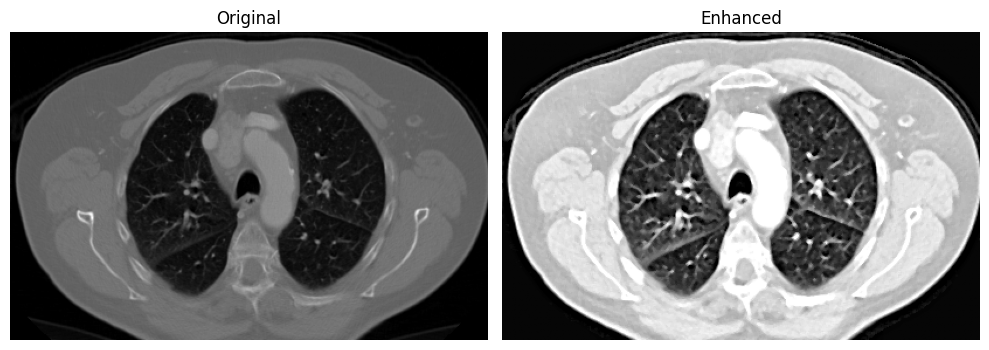

Enhancement verified ✓


In [4]:
def window_level(img):
    img    = img.astype(np.float32)
    p_low  = np.percentile(img, 5)
    p_high = np.percentile(img, 95)
    img    = np.clip(img, p_low, p_high)
    img    = ((img - p_low) / (p_high - p_low + 1e-8) * 255)
    return img.astype(np.uint8)


def lung_segmentation(img):
    _, binary = cv2.threshold(
        img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(
                cv2.MORPH_ELLIPSE, (15, 15))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img
    top2 = sorted(contours, key=cv2.contourArea,
                  reverse=True)[:2]
    mask = np.zeros_like(img)
    cv2.drawContours(mask, top2, -1, 255, -1)
    kernel2 = cv2.getStructuringElement(
                 cv2.MORPH_ELLIPSE, (20, 20))
    mask = cv2.dilate(mask, kernel2, iterations=1)
    result = cv2.bitwise_and(img, mask)
    if result.sum() < img.sum() * 0.1:
        return img
    return result


def multiscale_clahe(img):
    c1 = cv2.createCLAHE(clipLimit=1.0,
                          tileGridSize=(4,4)).apply(img)
    c2 = cv2.createCLAHE(clipLimit=2.0,
                          tileGridSize=(8,8)).apply(img)
    c3 = cv2.createCLAHE(clipLimit=3.0,
                          tileGridSize=(16,16)).apply(img)
    return (0.3*c1 + 0.4*c2 + 0.3*c3).astype(np.uint8)


def full_enhancement_pipeline(img_array):
    img = img_array.astype(np.uint8)
    img = window_level(img)
    img = cv2.medianBlur(img, 3)
    img = lung_segmentation(img)
    img = multiscale_clahe(img)
    blurred = cv2.GaussianBlur(img, (0,0), 3)
    img = cv2.addWeighted(img, 1.5, blurred, -0.5, 0)
    img = np.clip(img, 0, 255).astype(np.uint8)
    table = np.array([
        ((i/255.0)**(1.0/1.2))*255 for i in range(256)
    ]).astype(np.uint8)
    img = cv2.LUT(img, table)
    img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
    return img


# Verify pipeline
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sample = cv2.imread(all_paths[0], cv2.IMREAD_GRAYSCALE)
axes[0].imshow(sample, cmap='gray')
axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(full_enhancement_pipeline(sample), cmap='gray')
axes[1].set_title('Enhanced'); axes[1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "enhancement_check.png"), dpi=150)
plt.show()
print("Enhancement verified ✓")

In [5]:
class LungCancerDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None, augment=False):
        self.image_paths = image_paths
        self.labels      = labels
        self.transform   = transform
        self.augment     = augment

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx], cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = np.array(Image.open(self.image_paths[idx]).convert('L'))
        img = full_enhancement_pipeline(img)
        image = Image.fromarray(img).convert('RGB')  # Conformer expects 3ch
        if self.augment:
            image = self._augment(image)
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.labels[idx], dtype=torch.long)

    def _augment(self, image):
        img  = np.array(image, dtype=np.float32)
        h, w = img.shape[0], img.shape[1]

        angle = np.random.uniform(-15, 15)
        M_rot = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
        img   = cv2.warpAffine(img, M_rot, (w, h))

        tx, ty = np.random.randint(-15,16), np.random.randint(-15,16)
        M_tr = np.float32([[1,0,tx],[0,1,ty]])
        img  = cv2.warpAffine(img, M_tr, (w, h))

        sc = np.random.uniform(0.85, 1.15)
        nh, nw = int(h*sc), int(w*sc)
        img = cv2.resize(img, (nw, nh))
        if sc > 1:
            img = img[(nh-h)//2:(nh-h)//2+h, (nw-w)//2:(nw-w)//2+w]
        else:
            ph, pw = (h-nh)//2, (w-nw)//2
            img = np.pad(img, ((ph,h-nh-ph),(pw,w-nw-pw),(0,0)),
                         constant_values=0)

        if np.random.rand() > 0.5:
            img = np.fliplr(img).copy()

        img = np.clip(img * np.random.uniform(0.8, 1.2), 0, 255)
        return Image.fromarray(img[:h,:w].astype(np.uint8))


train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

train_loader = DataLoader(
    LungCancerDataset(tr_paths, tr_labels, train_transform, augment=True),
    batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
val_loader = DataLoader(
    LungCancerDataset(vl_paths, vl_labels, eval_transform, augment=False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(
    LungCancerDataset(ts_paths, ts_labels, eval_transform, augment=False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train : {len(train_loader)} batches ({len(tr_paths)} images)")
print(f"Val   : {len(val_loader)} batches ({len(vl_paths)} images)")
print(f"Test  : {len(test_loader)} batches ({len(ts_paths)} images)")
print("DataLoaders ready ✓")

Train : 44 batches (700 images)
Val   : 10 batches (150 images)
Test  : 10 batches (150 images)
DataLoaders ready ✓


In [6]:
class ConvStem(nn.Module):
    """CNN stem — extracts local features before splitting into branches"""
    def __init__(self, in_ch=3, out_ch=64):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 32, 3, stride=2, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, out_ch, 3, stride=2, padding=1)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.pool  = nn.MaxPool2d(3, stride=2, padding=1)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)
        return x   # /8 resolution


class ConvBlock(nn.Module):
    """Local CNN branch — residual bottleneck block"""
    def __init__(self, channels, stride=1):
        super().__init__()
        mid = channels // 4
        self.conv1 = nn.Conv2d(channels, mid, 1)
        self.bn1   = nn.BatchNorm2d(mid)
        self.conv2 = nn.Conv2d(mid, mid, 3, stride=stride, padding=1)
        self.bn2   = nn.BatchNorm2d(mid)
        self.conv3 = nn.Conv2d(mid, channels, 1)
        self.bn3   = nn.BatchNorm2d(channels)
        self.downsample = None
        if stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(channels, channels, 1, stride=stride),
                nn.BatchNorm2d(channels))

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return F.relu(out + identity)


class MultiHeadAttention(nn.Module):
    def __init__(self, dim, num_heads=8, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim  = dim // num_heads
        self.scale     = self.head_dim ** -0.5
        self.qkv       = nn.Linear(dim, dim * 3)
        self.proj      = nn.Linear(dim, dim)
        self.dropout   = nn.Dropout(dropout)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(
            B, N, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2,-1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.dropout(attn)
        out = (attn @ v).transpose(1,2).reshape(B, N, C)
        return self.proj(out)


class TransformerBlock(nn.Module):
    """Global Transformer branch — self-attention block"""
    def __init__(self, dim, num_heads=8, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = MultiHeadAttention(dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * mlp_ratio, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


class FeatureCoupling(nn.Module):
    """
    Couples CNN feature map with Transformer tokens.
    CNN → Transformer: project conv features to patch tokens
    Transformer → CNN: project tokens back to conv feature map
    """
    def __init__(self, conv_dim, trans_dim):
        super().__init__()
        self.conv_to_trans = nn.Conv2d(conv_dim, trans_dim, 1)
        self.trans_to_conv = nn.Conv2d(trans_dim, conv_dim, 1)

    def conv2trans(self, conv_feat):
        # B,C,H,W -> B,N,C (patch tokens)
        x = self.conv_to_trans(conv_feat)
        B, C, H, W = x.shape
        return x.flatten(2).transpose(1, 2), (H, W)

    def trans2conv(self, trans_feat, hw):
        # B,N,C -> B,C,H,W
        H, W = hw
        B, N, C = trans_feat.shape
        x = trans_feat.transpose(1, 2).reshape(B, C, H, W)
        return self.trans_to_conv(x)


class ConformerLungCancer(nn.Module):
    """
    Conformer-style architecture for lung cancer classification.
    Dual branch: CNN (local features) + Transformer (global context)
    with feature coupling between branches at each stage.
    """
    def __init__(self, num_classes=4, conv_dim=256, trans_dim=384,
                 num_heads=8, num_blocks=6, dropout_rate=0.3, img_size=224):
        super().__init__()

        # Stem: shared initial feature extraction
        self.stem = ConvStem(in_ch=3, out_ch=conv_dim)

        # Initial projection to transformer dimension
        self.coupling_init = FeatureCoupling(conv_dim, trans_dim)

        # Class token + positional embedding (set dynamically)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, trans_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)

        # Dual-branch blocks
        self.conv_blocks  = nn.ModuleList(
            [ConvBlock(conv_dim) for _ in range(num_blocks)])
        self.trans_blocks = nn.ModuleList(
            [TransformerBlock(trans_dim, num_heads, dropout=dropout_rate)
             for _ in range(num_blocks)])
        self.couplings = nn.ModuleList(
            [FeatureCoupling(conv_dim, trans_dim)
             for _ in range(num_blocks)])

        # stem downsamples by 8 -> (img_size//8)^2 patch tokens + 1 cls token
        # registered as a real Parameter so it is trained AND saved in the .pth
        num_tokens = 1 + (img_size // 8) ** 2
        self.pos_embed = nn.Parameter(torch.zeros(1, num_tokens, trans_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        # Final heads
        self.conv_pool  = nn.AdaptiveAvgPool2d(1)
        self.norm_trans = nn.LayerNorm(trans_dim)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(conv_dim + trans_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(256, num_classes)
        )

        self.last_conv_features = None  # for Grad-CAM

    def forward(self, x):
        B = x.shape[0]

        # Stem
        conv_feat = self.stem(x)             # B, conv_dim, H, W

        # Initialize transformer tokens from conv features
        trans_tokens, hw = self.coupling_init.conv2trans(conv_feat)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        trans_tokens = torch.cat([cls_tokens, trans_tokens], dim=1)

        trans_tokens = trans_tokens + self.pos_embed

        # Dual-branch processing with feature coupling
        for conv_blk, trans_blk, coupling in zip(
                self.conv_blocks, self.trans_blocks, self.couplings):

            conv_feat = conv_blk(conv_feat)
            trans_tokens = trans_blk(trans_tokens)

            # Couple: inject conv info into transformer patch tokens
            patch_tokens = trans_tokens[:, 1:, :]   # exclude cls token
            extra, _ = coupling.conv2trans(conv_feat)
            patch_tokens = patch_tokens + 0.1 * extra
            trans_tokens = torch.cat(
                [trans_tokens[:, :1, :], patch_tokens], dim=1)

        self.last_conv_features = conv_feat   # for Grad-CAM

        # Final pooling
        conv_out  = self.conv_pool(conv_feat).flatten(1)   # B, conv_dim
        trans_out = self.norm_trans(trans_tokens[:, 0])    # B, trans_dim (cls token)

        # Concatenate both branches
        combined = torch.cat([conv_out, trans_out], dim=1)
        return self.classifier(combined)


model = ConformerLungCancer(
    num_classes=NUM_CLASSES,
    conv_dim=128,
    trans_dim=192,
    num_heads=6,
    num_blocks=4,
    dropout_rate=DROPOUT_RATE,
    img_size=IMAGE_SIZE
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model ready ✓  |  Parameters: {total_params:,}")
print(f"Running on    : {next(model.parameters()).device}")

Model ready ✓  |  Parameters: 2,371,460
Running on    : cuda:0


In [7]:
if os.path.exists(MODEL_PATH):
    os.remove(MODEL_PATH)
    print("Old model deleted ✓")

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(
    model.parameters(),
    lr=INITIAL_LR,
    weight_decay=5e-4)
scheduler = CosineAnnealingLR(
    optimizer, T_max=MAX_EPOCHS, eta_min=1e-7)

history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}
best_val_acc, best_weights = 0.0, None
patience, patience_counter = 30, 0

for epoch in range(MAX_EPOCHS):
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for imgs, lbls in tqdm(train_loader,
                           desc=f"Epoch {epoch+1:03d}/{MAX_EPOCHS}",
                           leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        out  = model(imgs)
        loss = criterion(out, lbls)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr_loss    += loss.item() * imgs.size(0)
        tr_correct += out.argmax(1).eq(lbls).sum().item()
        tr_total   += lbls.size(0)

    model.eval()
    vl_loss, vl_correct, vl_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out  = model(imgs)
            loss = criterion(out, lbls)
            vl_loss    += loss.item() * imgs.size(0)
            vl_correct += out.argmax(1).eq(lbls).sum().item()
            vl_total   += lbls.size(0)

    tr_acc = 100 * tr_correct / tr_total
    vl_acc = 100 * vl_correct / vl_total
    history["train_loss"].append(tr_loss / tr_total)
    history["val_loss"].append(vl_loss / vl_total)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(vl_acc)
    scheduler.step()

    if vl_acc > best_val_acc:
        best_val_acc     = vl_acc
        patience_counter = 0
        best_weights = {k: v.cpu().clone()
                        for k, v in model.state_dict().items()}
        torch.save(best_weights, MODEL_PATH)
        print(f"  Epoch {epoch+1:3d} ✓  "
              f"train={tr_acc:.1f}%  val={vl_acc:.1f}%  ← best saved")
    else:
        patience_counter += 1
        if (epoch+1) % 10 == 0:
            print(f"  Epoch {epoch+1:3d}    "
                  f"train={tr_acc:.1f}%  val={vl_acc:.1f}%  "
                  f"(patience {patience_counter}/{patience})")

    if patience_counter >= patience:
        print(f"\n  Early stopping at epoch {epoch+1}")
        break

model.load_state_dict(best_weights)

print(f"\n{'='*55}")
print(f"Training complete ✓")
print(f"Best val acc  : {best_val_acc:.2f}%")
print(f"Total epochs  : {len(history['train_acc'])}")
print(f"Max train acc : {max(history['train_acc']):.1f}%")
print(f"Max val acc   : {max(history['val_acc']):.1f}%")
print(f"{'='*55}")

  Epoch   1 ✓  train=39.6%  val=28.0%  ← best saved


  Epoch   2 ✓  train=42.3%  val=40.0%  ← best saved


  Epoch   4 ✓  train=53.4%  val=41.3%  ← best saved


  Epoch   6 ✓  train=55.9%  val=42.7%  ← best saved


  Epoch   8 ✓  train=60.3%  val=58.0%  ← best saved


  Epoch   9 ✓  train=61.4%  val=59.3%  ← best saved


... (19 outputs left out)

  Epoch 100 ✓  train=90.9%  val=94.0%  ← best saved


  Epoch 110    train=92.7%  val=91.3%  (patience 10/30)


  Epoch 120    train=92.9%  val=88.0%  (patience 20/30)


  Epoch 130    train=92.1%  val=90.0%  (patience 30/30)

  Early stopping at epoch 130

Training complete ✓
Best val acc  : 94.00%
Total epochs  : 130
Max train acc : 94.7%
Max val acc   : 94.0%


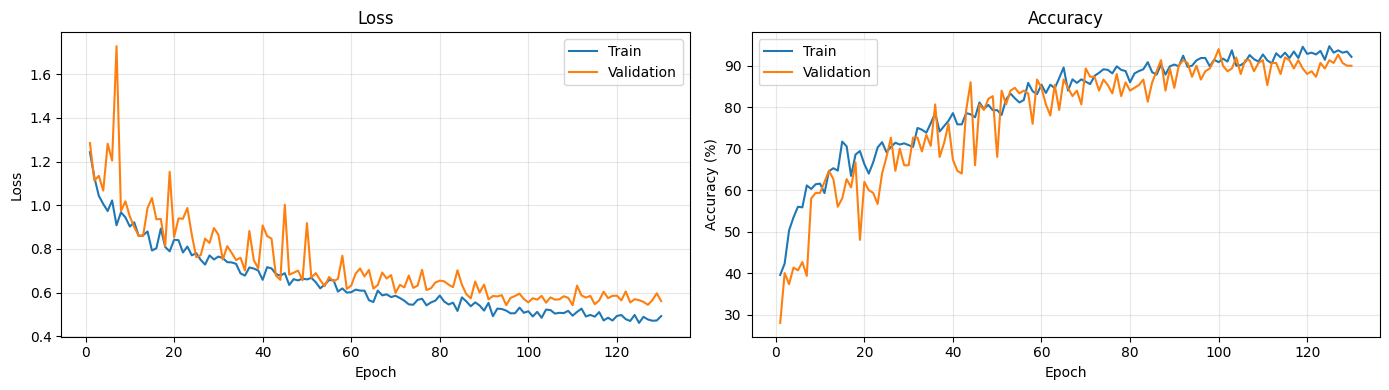

Saved ✓


In [8]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"],   label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"],   label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_history.png"), dpi=150)
plt.show()
print("Saved ✓")

In [9]:
model.eval()
all_preds, all_labels_list, all_probs = [], [], []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader, desc="Testing"):
        imgs  = imgs.to(device)
        out   = model(imgs)
        probs = torch.softmax(out, dim=1)
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels_list.extend(lbls.numpy())
        all_probs.extend(probs.cpu().numpy())

preds  = np.array(all_preds)
labels = np.array(all_labels_list)
probs  = np.array(all_probs)

overall_acc = accuracy_score(labels, preds) * 100
macro_prec  = precision_score(labels, preds, average='macro', zero_division=0) * 100
macro_rec   = recall_score(labels, preds, average='macro', zero_division=0) * 100
macro_f1    = f1_score(labels, preds, average='macro', zero_division=0) * 100

print(f"\n{'='*57}")
print(f"Overall Accuracy : {overall_acc:.2f}%")
print(f"Macro Precision  : {macro_prec:.2f}%")
print(f"Macro Recall     : {macro_rec:.2f}%")
print(f"Macro F1-Score   : {macro_f1:.2f}%")
print(f"{'='*57}")

for i, cls in enumerate(CLASS_NAMES):
    bl      = (labels == i).astype(int)
    bp      = (preds  == i).astype(int)
    auc_val = roc_auc_score(bl, probs[:, i]) if len(np.unique(bl)) > 1 else 0.0
    print(f"\n{cls}:")
    print(f"  Precision  : {precision_score(bl, bp, zero_division=0):.4f}")
    print(f"  Recall     : {recall_score(bl, bp, zero_division=0):.4f}")
    print(f"  F1-Score   : {f1_score(bl, bp, zero_division=0):.4f}")
    print(f"  Specificity: {recall_score(1-bl, 1-bp, zero_division=0):.4f}")
    print(f"  AUC-ROC    : {auc_val:.4f}")

Testing: 100%|██████████| 10/10 [00:10<00:00,  1.02s/it]


Overall Accuracy : 95.33%
Macro Precision  : 95.29%
Macro Recall     : 96.42%
Macro F1-Score   : 95.70%

adenocarcinoma:
  Precision  : 1.0000
  Recall     : 0.8824
  F1-Score   : 0.9375
  Specificity: 1.0000
  AUC-ROC    : 0.9931

large_cell_carcinoma:
  Precision  : 0.9655
  Recall     : 1.0000
  F1-Score   : 0.9825
  Specificity: 0.9918
  AUC-ROC    : 0.9994

squamous_cell_carcinoma:
  Precision  : 0.9048
  Recall     : 0.9744
  F1-Score   : 0.9383
  Specificity: 0.9640
  AUC-ROC    : 0.9880

normal:
  Precision  : 0.9412
  Recall     : 1.0000
  F1-Score   : 0.9697
  Specificity: 0.9831
  AUC-ROC    : 0.9989


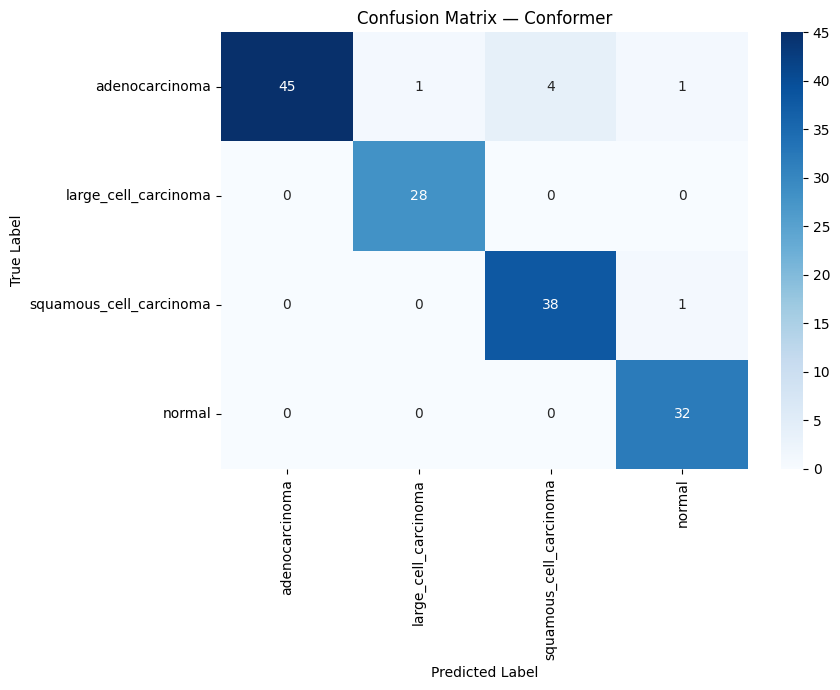

Saved ✓


In [10]:
cm = confusion_matrix(labels, preds, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(ylabel='True Label', xlabel='Predicted Label',
       title='Confusion Matrix — Conformer')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()
print("Saved ✓")

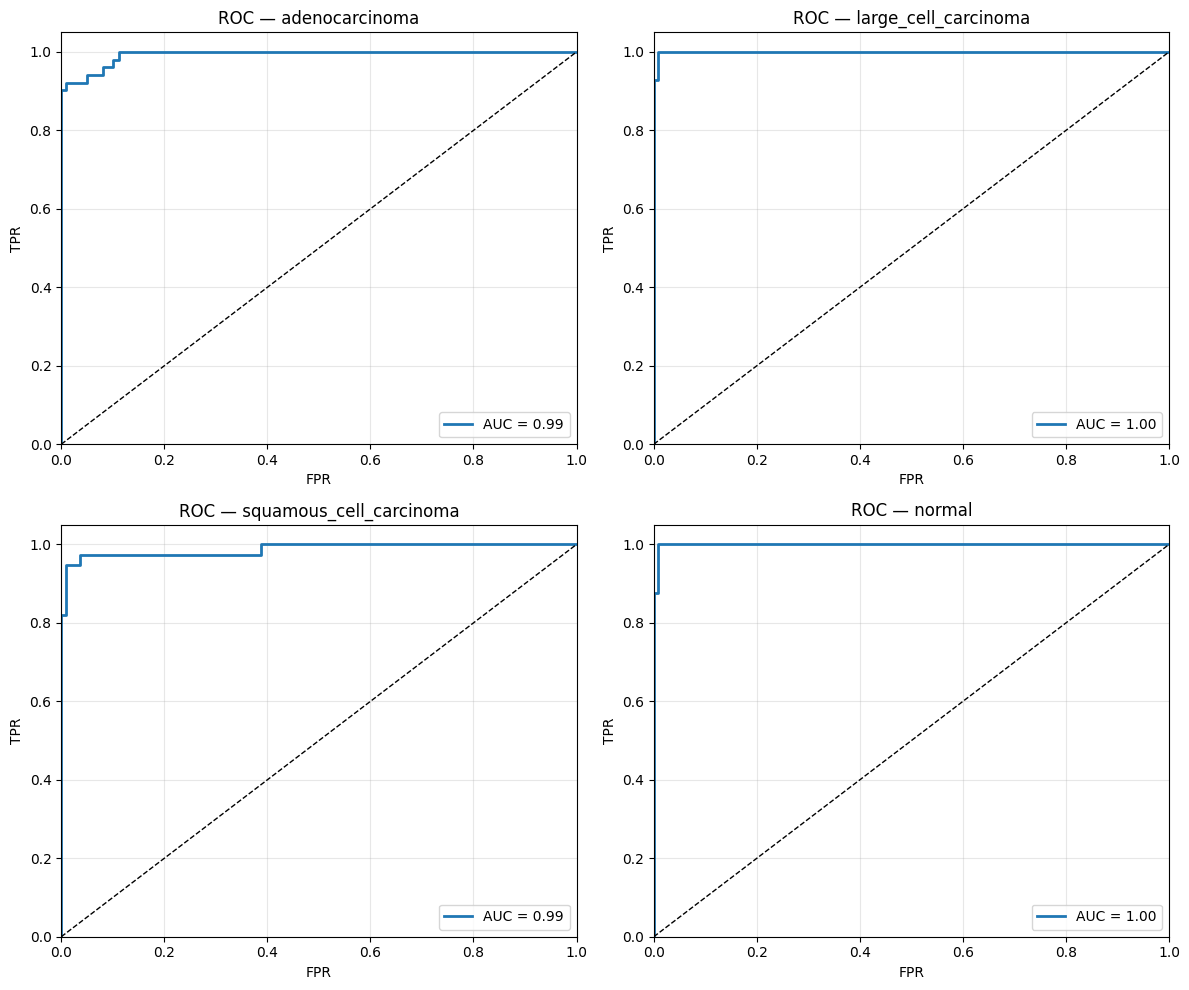

Saved ✓


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for i, cls in enumerate(CLASS_NAMES):
    bl  = (labels == i).astype(int)
    fpr, tpr, _ = roc_curve(bl, probs[:, i])
    roc_auc = auc(fpr, tpr)
    axes[i].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f}')
    axes[i].plot([0,1],[0,1],'k--', lw=1)
    axes[i].set(title=f'ROC — {cls}', xlabel='FPR', ylabel='TPR',
                xlim=[0,1], ylim=[0,1.05])
    axes[i].legend(loc='lower right')
    axes[i].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curves.png"), dpi=150)
plt.show()
print("Saved ✓")

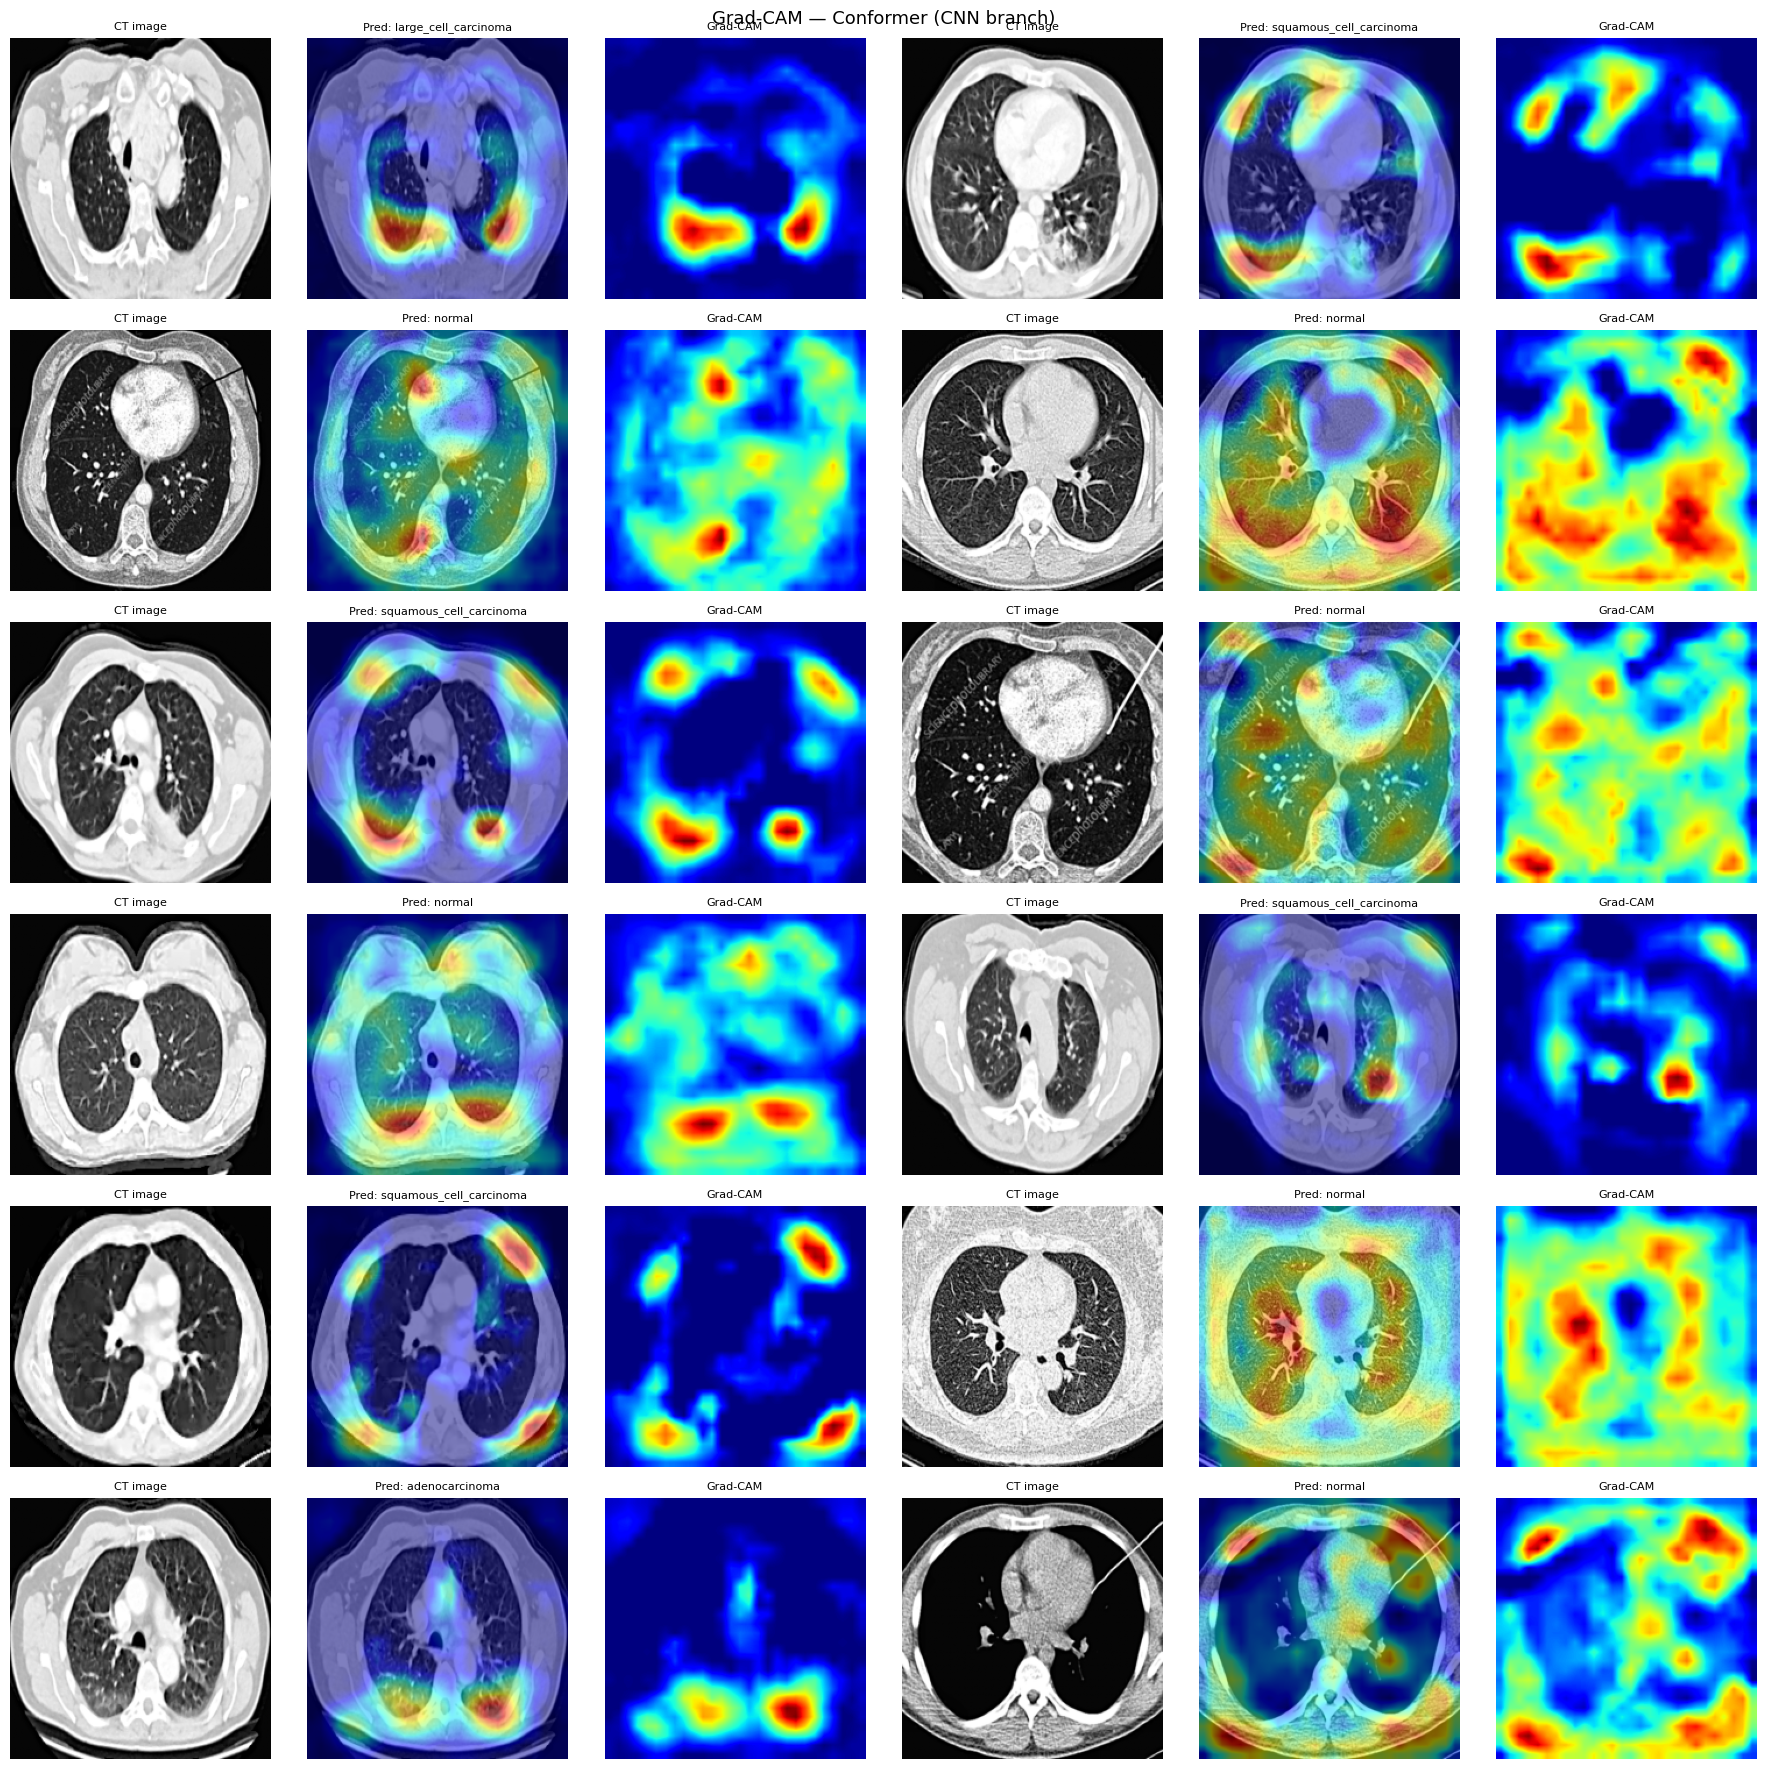

All outputs saved to /kaggle/working/outputs/ ✓


In [12]:
class GradCAM:
    def __init__(self, model, device):
        self.model       = model
        self.device      = device
        self.gradients   = None
        self.activations = None
        # Hook last CNN block (local branch)
        target = model.conv_blocks[-1]
        target.register_forward_hook(self._fwd)
        target.register_backward_hook(self._bwd)

    def _fwd(self, m, inp, out):
        self.activations = out.detach()

    def _bwd(self, m, gi, go):
        self.gradients = go[0].detach()

    def generate(self, img_tensor, target_class=None):
        self.model.eval()
        out = self.model(img_tensor)
        if target_class is None:
            target_class = out.argmax(1).item()
        self.model.zero_grad()
        out[0, target_class].backward()
        weights = self.gradients[0].mean(dim=(1,2))
        cam = (weights[:,None,None] * self.activations[0]).sum(0)
        cam = F.relu(cam)
        mn, mx = cam.min(), cam.max()
        if mx > mn:
            cam = (cam - mn) / (mx - mn)
        return cam.cpu().numpy(), target_class


gc  = GradCAM(model, device)
fig, axes = plt.subplots(6, 6, figsize=(18, 18)) # Changed from (4, 6) to (6, 6) and figsize to (18, 18)
sample_count = 0

for imgs, lbls in test_loader:
    imgs = imgs.to(device)
    for i in range(imgs.size(0)):
        if sample_count >= 12:
            break
        img = imgs[i:i+1]
        cam, pred = gc.generate(img)

        orig        = imgs[i, 0].cpu().numpy()
        cam_resized = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE))
        heatmap     = plt.get_cmap('jet')(cam_resized)[:,:,:3]
        orig_3ch    = np.stack([orig]*3, axis=-1)
        orig_3ch    = (orig_3ch - orig_3ch.min()) / \
                      (orig_3ch.max() - orig_3ch.min() + 1e-8)
        overlay     = 0.5*orig_3ch + 0.5*heatmap

        row = sample_count // 2
        c0  = (sample_count % 2) * 3

        axes[row][c0].imshow(orig, cmap='gray')
        axes[row][c0].set_title('CT image', fontsize=8)
        axes[row][c0].axis('off')

        axes[row][c0+1].imshow(overlay)
        axes[row][c0+1].set_title(f'Pred: {CLASS_NAMES[pred]}', fontsize=8)
        axes[row][c0+1].axis('off')

        axes[row][c0+2].imshow(cam_resized, cmap='jet')
        axes[row][c0+2].set_title('Grad-CAM', fontsize=8)
        axes[row][c0+2].axis('off')

        sample_count += 1
    if sample_count >= 12:
        break

plt.suptitle('Grad-CAM — Conformer (CNN branch)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "grad_cam.png"), dpi=150)
plt.show()
print("All outputs saved to /kaggle/working/outputs/ ✓")

## Grad-CAM for a chosen test image

In [13]:
def list_images(split="test"):
    """All images of one split of the ORIGINAL Kaggle folder structure."""
    items = []
    for folder in ALL_CLASS_MAP:
        d = os.path.join(BASE, split, folder)
        if os.path.isdir(d):
            items += [os.path.join(d, f) for f in sorted(os.listdir(d))
                      if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    return items


def infer_true_label(path):
    """Ground truth from the class folder name in the path (if present)."""
    parts = path.replace("\\", "/").split("/")
    for folder, idx in ALL_CLASS_MAP.items():
        if folder in parts:
            return CLASS_NAMES[idx]
    return None


def explain_image(img_path, true_label=None, target_class=None, save=True):
    """Prediction + class probabilities + Grad-CAM for ONE image file."""
    # same preprocessing as the dataset class
    raw = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        raw = np.array(Image.open(img_path).convert("L"))
    enhanced = full_enhancement_pipeline(raw)
    x = eval_transform(Image.fromarray(enhanced).convert("RGB")).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    pred = int(probs.argmax())

    cam, cls_used = gc.generate(x, target_class=target_class)   # needs grad
    cam_resized = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE))
    heatmap = plt.get_cmap("jet")(cam_resized)[:, :, :3]
    base = cv2.resize(enhanced, (IMAGE_SIZE, IMAGE_SIZE)).astype(np.float32) / 255.0
    overlay = 0.5 * np.stack([base] * 3, -1) + 0.5 * heatmap

    true_label = true_label or infer_true_label(img_path)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    axes[0].imshow(raw, cmap="gray");       axes[0].set_title("Input CT image")
    axes[1].imshow(enhanced, cmap="gray");  axes[1].set_title("After enhancement (model input)")
    axes[2].imshow(overlay)
    t = f"Grad-CAM -> {CLASS_NAMES[cls_used]}"
    if true_label: t += f"\nTrue: {true_label}"
    axes[2].set_title(t)
    colors = ["tab:blue"] * len(CLASS_NAMES); colors[pred] = "tab:red"
    axes[3].barh(CLASS_NAMES, probs * 100, color=colors)
    axes[3].set_xlim(0, 100); axes[3].invert_yaxis()
    axes[3].set_xlabel("Probability (%)")
    axes[3].set_title(f"Prediction: {CLASS_NAMES[pred]} ({probs[pred]*100:.1f}%)")
    for a in axes[:3]: a.axis("off")
    plt.tight_layout()
    if save:
        name = os.path.splitext(os.path.basename(img_path))[0]
        plt.savefig(os.path.join(OUTPUT_DIR, f"gradcam_{name}.png"), dpi=150)
    plt.show()
    print(f"{os.path.basename(img_path)} -> {CLASS_NAMES[pred]} ({probs[pred]*100:.1f}%)")
    return pred, probs, cam_resized

print("explain_image ready ✓")

explain_image ready ✓


315 images in the Kaggle test folder
/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data/test/normal/10 (2) - Copy.png
/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data/test/normal/10 (2).png
/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data/test/normal/10 - Copy (2) - Copy.png
/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data/test/normal/10 - Copy (2).png
/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data/test/normal/10 - Copy (3).png


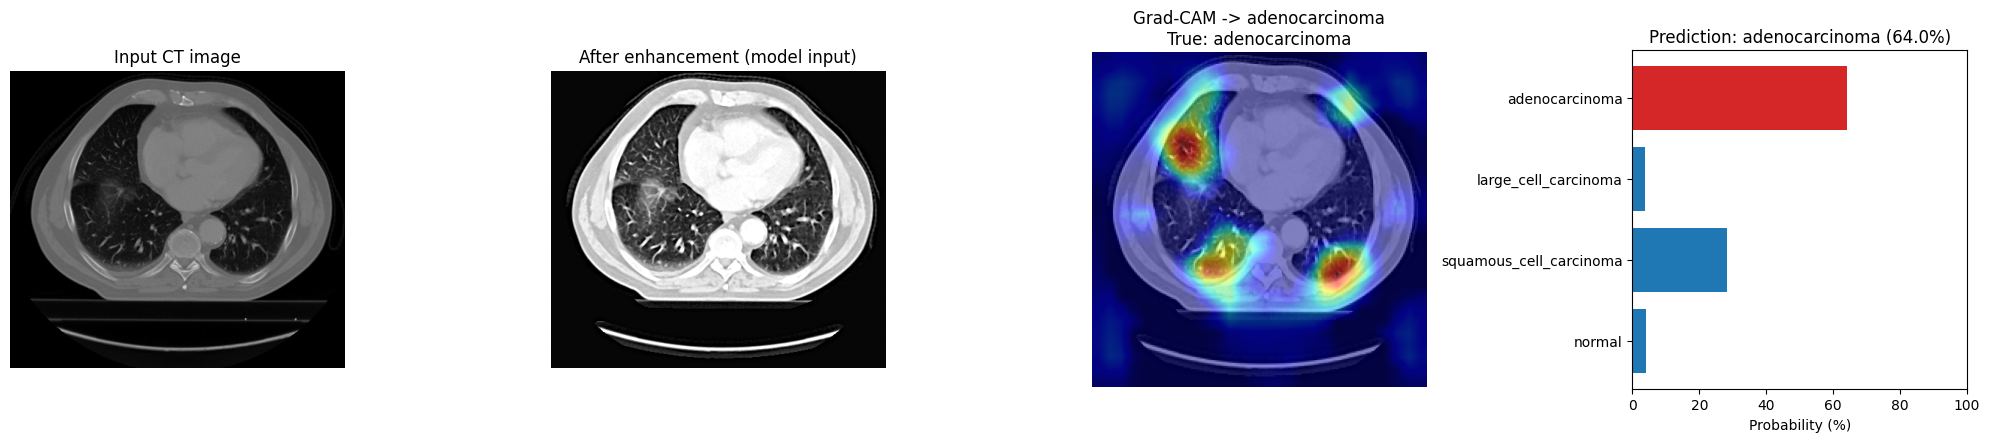

000109 (5).png -> adenocarcinoma (64.0%)


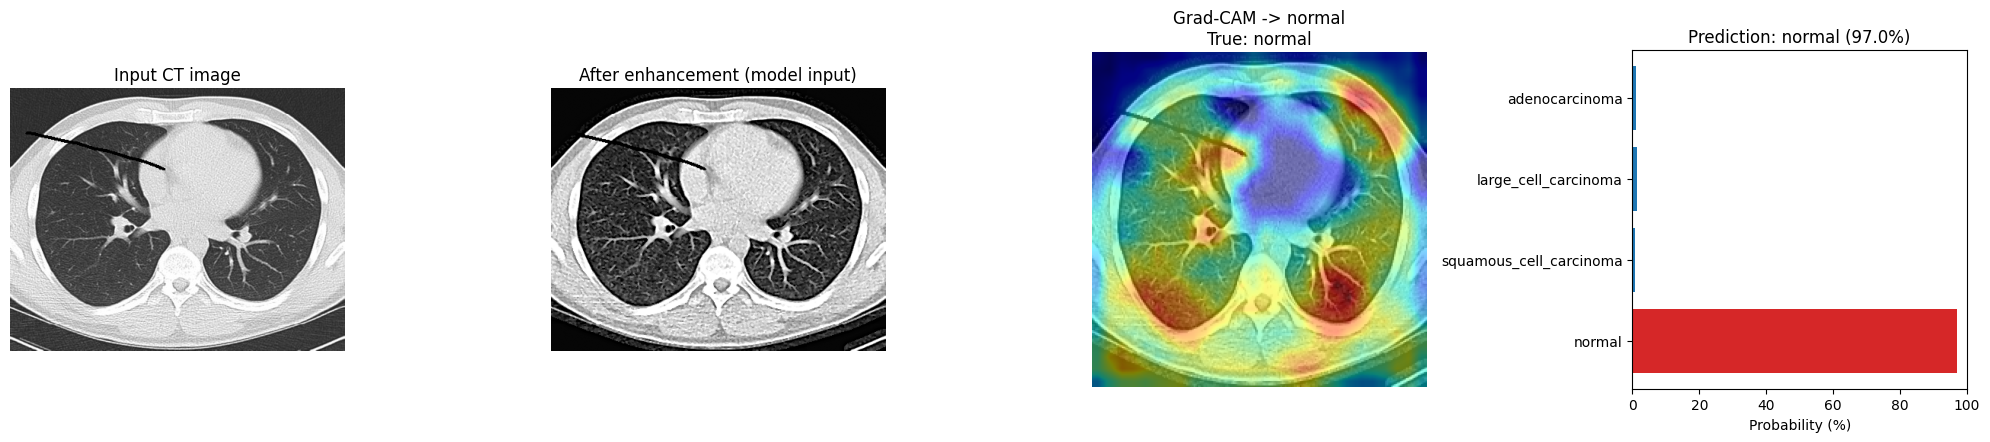

11 - Copy (3).png -> normal (97.0%)


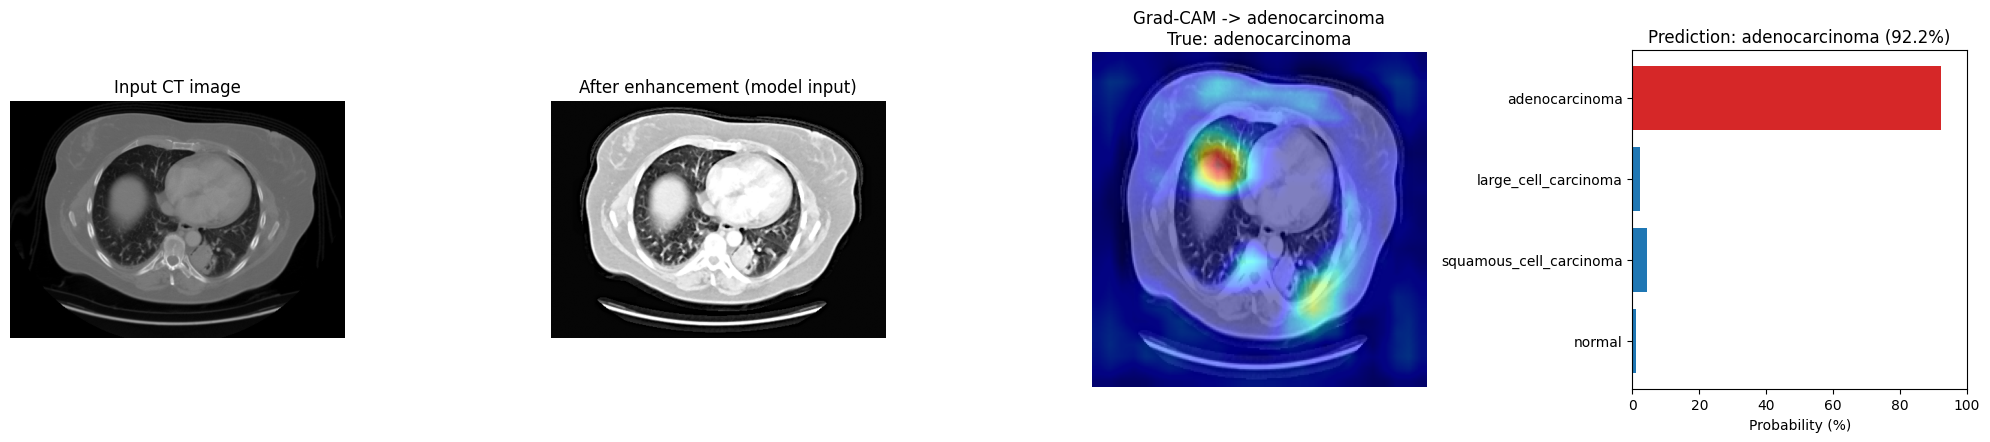

000153 (5).png -> adenocarcinoma (92.2%)


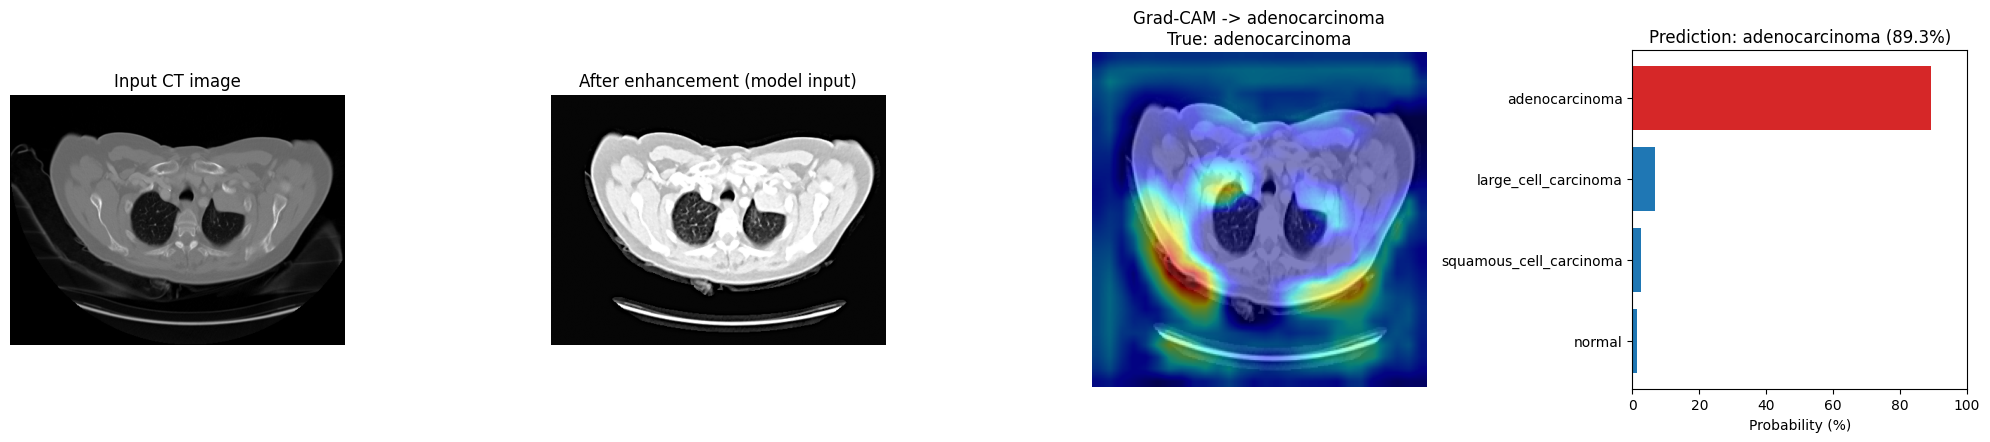

000143 (6).png -> adenocarcinoma (89.3%)


In [14]:
# ---- Option 1: one specific image from the Kaggle test folder ----
# Browse the exact file names first:
test_files = list_images("test")
print(len(test_files), "images in the Kaggle test folder")
for p in test_files[:5]:
    print(p)

# explain_image(test_files[0])
# explain_image(f"{BASE}/test/normal/<your_file>.png")

# ---- Option 2: random Kaggle-test images (one run = 4 images) ----
for p in random.sample(test_files, 4):
    explain_image(p)

# ---- Option 3: images this model has NEVER seen ----
# Your notebook pools train+valid+test and re-splits 70/15/15, so images from the
# original Kaggle test folder can be in your training set. ts_paths is the true hold-out.
# for p in random.sample(ts_paths, 4):
#     explain_image(p)

# ---- Option 4: your own image: + Add Input -> Upload, then use its /kaggle/input/... path
# explain_image("/kaggle/input/<your-upload>/<file>.png")

# ---- Reload a saved model later (new session): run the model + GradCAM cells first, then
# model.load_state_dict(torch.load(MODEL_PATH, map_location=device)); model.eval()